U fajlu “Disneyland_reviews_for_class.csv” su dati podaci o komentarima posetilaca Disneyland parkova. Fajl sadrzi sledece kolone (varijable):
- Review_ID - jedinstveni identifikator komentara
- Rating - ocena koju je posetilac dao parku
- Year_Month - godina i mesec posete na koju se komentar odnosi
- Reviewer_Location - drzava iz koje je autor komentara
- Review_Test - tekst komentara
- Branch - ogranak Disneyland parka koji je predmet komentara

Koristeci opisane podatke iz navedenog fajla, potrebno je uraditi sledece:
- Polazeci od kolone Rating napraviti novu `sentiment varijablu` sa tri moguce vrednosti (negativan, neutralan, pozitivan) primenjujuci sledeće mapiranje:
    - rating 1 i 2 se mapiraju u “negativan” sentiment,
    - rating 3 se mapira u “neutralan” sentiment,
    - rating 4 i 5 se mapiraju u “pozitivan” sentiment
Varijabla sentiment bi trebalo da posluzi kao izlazna varijabla za klasifikaciju u ovom zadatku.
- Transformisati kolonu Review_Text u numericki oblik primenom Bag of Words modela i konkretno, `TF` metrike za procenu znacajnosti reci. Takodje, proceniti da li bi jos neku od varijabli iz polaznog dataset-a trebalo primeniti za kreiranje modela i ako se opredelite da neku/neke varijable ukljucite, obrazlozite ukratko odluku.
- Kreirati prvi klasifikacioni model primenom algoritma `Support Vector Machines (SVM)`, sa `linearnim kernelom` i `podrazumevanim vrednostima hiperparametara`.
- Napraviti predikcije primenom kreiranog modela i izracunati standardne `evaluacione metrike` (preciznost, odziv, F1) kako za svaku klasu pojedinačno, tako i sveukupno tj na nivou svih klasa. `Interpretirati` dobijene vrednosti metrika u kontekstu zadatka.
- Kreirati drugi klasifikacioni model kroz postupak `podesavanja hiperparametara`. U komentaru navesti koje biste hiperparametre podesavali i na koji nacin tj koristeci koje opsege/liste vrednosti ako ne biste bili vremenski ograniceni. Zatim, izabrati `dva hiperparametra`, jedan za transformaciju teksta, drugi za klasifikator, odnosno oba za klasifikator ako hiperparametri nisu primenljivi za transformaciju teksta, i izvrsite podesavanje njihovih vrednosti kroz postupak (5-fold) `kros-validacije`.
- Izvrsiti predikcije primenom podesenog modela i izracunati standardne evaluacione metrike (preciznost, odziv, F1) kako za svaku klasu pojedinačno, tako i sveukupno tj na nivou svih klasa.
- `Uporediti` i prokomentarisati rezultate dobijene osnovnim i podesenim modelima.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.svm import SVC

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path

import spacy

from Klasifikacija import best_mindf, best_C

In [2]:
RAND_STATE = 1

SPACY_MODEL = 'en_core_web_sm'

#### UCITAVANJE I PREGLED PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'Disneyland_reviews_for_class.csv')

data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,532711443,5,2017-9,United States,We've been coming since our grown kids were yo...,Disneyland_California
1,230885912,5,2014-5,United States,"Yes, it's crowded and the lines are long and e...",Disneyland_California
2,130119156,4,2012-5,Ireland,We're just back from Disneyland Paris and we h...,Disneyland_Paris
3,472057505,4,2017-4,Philippines,We were surprised that we didn't have to wait ...,Disneyland_HongKong
4,385661044,5,2015-7,United States,I can't say enough about this place. When I ev...,Disneyland_California


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Review_ID          3000 non-null   int64 
 1   Rating             3000 non-null   int64 
 2   Year_Month         3000 non-null   object
 3   Reviewer_Location  3000 non-null   object
 4   Review_Text        3000 non-null   object
 5   Branch             3000 non-null   object
dtypes: int64(2), object(4)
memory usage: 140.8+ KB


In [5]:
data.duplicated().sum()

np.int64(0)

#### KREIRANJE IZLAZNE VARIJABLE

In [6]:
def rating_to_sentiment(rating):
    if rating < 3: return 'NEGATIVE'
    return 'NEUTRAL' if rating == 3 else 'POSITIVE'


data['Sentiment'] = data.Rating.apply(rating_to_sentiment)

data[['Rating', 'Sentiment']].sample(5, random_state=RAND_STATE)

,Rating,Sentiment
1957,5,POSITIVE
2087,4,POSITIVE
1394,3,NEUTRAL
1520,2,NEGATIVE
1098,5,POSITIVE


In [7]:
data.Sentiment.value_counts(normalize=True)

Sentiment
POSITIVE    0.796333
NEUTRAL     0.120667
NEGATIVE    0.083000
Name: proportion, dtype: float64

Postoji izuzetno izrazena `nebalansiranost` klasa -> mozda cemo iskoristiti `SMOTE`.

#### PREDIKTORI

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Review_ID          3000 non-null   int64 
 1   Rating             3000 non-null   int64 
 2   Year_Month         3000 non-null   object
 3   Reviewer_Location  3000 non-null   object
 4   Review_Text        3000 non-null   object
 5   Branch             3000 non-null   object
 6   Sentiment          3000 non-null   object
dtypes: int64(2), object(5)
memory usage: 164.2+ KB


In [9]:
print('Broj jedinstvenih vrednosti u Year_Month koloni:', data.Year_Month.nunique())

Broj jedinstvenih vrednosti u Year_Month koloni: 107


In [10]:
print('Broj jedinstvenih vrednosti u Reviewer_Location koloni:', data.Reviewer_Location.nunique())

Broj jedinstvenih vrednosti u Reviewer_Location koloni: 86


In [11]:
print('Broj jedinstvenih vrednosti u Branch koloni:', data.Branch.nunique())

Broj jedinstvenih vrednosti u Branch koloni: 3


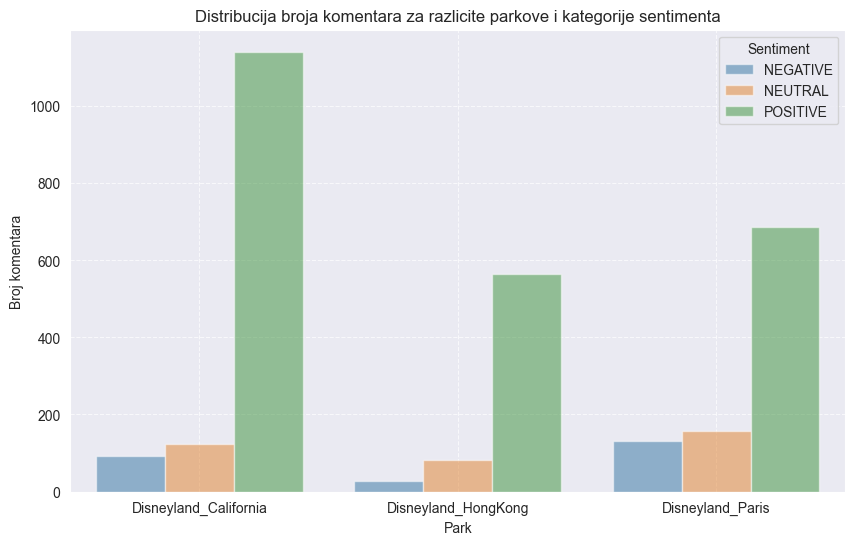

In [12]:
# grupisemo komentare po Branch i Sentimentu i racunamo broj komentara za svaku kombinaciju
branch_counts_df = (
    data.groupby(['Branch', 'Sentiment'])
    .size()
    .reset_index(name='Review_Count')
)

plt.figure(figsize=(10, 6))

sb.barplot(data=branch_counts_df,
           x='Branch',
           y='Review_Count',
           hue='Sentiment',
           fill=True,
           alpha=0.5)

plt.title('Distribucija broja komentara za razlicite parkove i kategorije sentimenta')
plt.xlabel('Park')
plt.ylabel('Broj komentara')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Kolona `Review_ID` prestavlja identifikator -> necemo je koristiti.

Kolona `Rating` je koriscena za kreiranje izlazne varijable -> necemo je koristiti.

Kolona `Year_Month` ima 107 jedinstvenih vrednosti -> necemo je koristiti.

Kolona `Review_Location` ima 86 jedinstvenih vrednosti -> necemo je koristiti.

Kolona `Branch` na osnovu prethodnog grafikona ne deluje da moze biti dobar prediktor (slicne proporcije po klasama) -> necemo je koristiti.

Na kraju kao prediktor koristimo samo kolonu `Review_Text`.

#### COLUMN TRANSFORMER

In [13]:
spacy_model = spacy.load(SPACY_MODEL, disable=['parser', 'ner'])

In [14]:
def spacy_tokenizer(doc):
    tokens = spacy_model(doc)
    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space) and (not token.like_num)
                  and (not token.like_url))]
    tokens = [token for token in tokens if ((not token.is_stop) or (token.lemma_.lower() == 'not'))]
    words = [token.lemma_.lower() for token in tokens]
    return words

In [15]:
def create_count_vectorizer(ngrams=(1, 2)):
    return CountVectorizer(
        tokenizer=spacy_tokenizer,
        token_pattern=None,
        ngram_range=ngrams
    )

#### PODELA NA TRAIN I TEST

In [16]:
X = data.Review_Text
y = data.Sentiment

y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encodings, test_size=0.2, random_state=RAND_STATE,
                                                    stratify=y_encodings)

#### KREIRANJE I TRENING PIPELINE-a

In [17]:
vectorizer = create_count_vectorizer()

smote = SMOTE(random_state=RAND_STATE)

classifier = SVC(random_state=RAND_STATE, kernel='linear')

svc_pipe = Pipeline(
    steps=[
        ('vectorizer', vectorizer),
        ('resampling', smote),
        ('classifier', classifier)
    ],
    verbose=True
)

svc_pipe.fit(X_train, y_train)

[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  26.6s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.1s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=  14.9s


,steps,"[('vectorizer', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...001D977E8E520>


#### PREDIKCIJE I EVALUACIJA MODELA

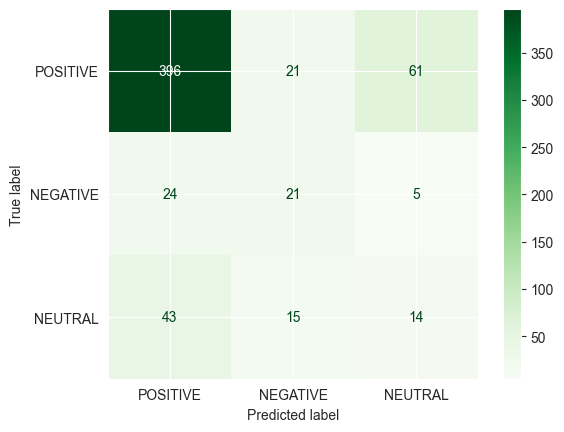

In [18]:
ConfusionMatrixDisplay.from_estimator(
    estimator=svc_pipe,
    X=X_test,
    y=y_test,
    display_labels=y_levels,
    cmap='Greens'
)

In [20]:
y_pred = svc_pipe.predict(X_test)

report1 = classification_report(y_true=y_test, y_pred=y_pred, target_names=y_levels)

print(report1)

              precision    recall  f1-score   support

    POSITIVE       0.86      0.83      0.84       478
    NEGATIVE       0.37      0.42      0.39        50
     NEUTRAL       0.17      0.19      0.18        72

    accuracy                           0.72       600
   macro avg       0.47      0.48      0.47       600
weighted avg       0.73      0.72      0.73       600



Klasa `POSITIVE`:
    - precisison _ - od svih komentara korisnika koje smo predvideli kao pozitivan sentiment(_+_+_), _% je stvarno pozitivno
    - recall _ - od svih komentara koji su pozitivan sentiment (_+_+_), _% smo tacno predvideli kao pozitivne
    - f1-score _ - pokazuje _ balansiranost izmedju precision i recall-a pri predvidjanju komentara pozitivnog sentimenta

Klasa `NEGATIVE`:
    - precisison _ - od svih komentara korisnika koje smo predvideli kao negativan sentiment(_+_+_), _% je stvarno negativno
    - recall _ - od svih komentara koji su negativan sentiment (_+_+_), _% smo tacno predvideli kao negativne
    - f1-score _ - pokazuje _ balansiranost izmedju precision i recall-a pri predvidjanju komentara negativnog sentimenta

Klasa `NEUTRAL`:
    - precisison _ - od svih komentara korisnika koje smo predvideli kao neutralan sentiment(_+_+_), _% je stvarno neutralno
    - recall _ - od svih komentara koji su neutralan sentiment (_+_+_), _% smo tacno predvideli kao neutralne
    - f1-score _ - pokazuje _ balansiranost izmedju precision i recall-a pri predvidjanju komentara neutralnog sentimenta

macro avg (f1-score) _ - _ sposobnost modela da razlikuje sentimente komentara korisnika
weighted avg (f1-score) - _ sposobnost modela da prepoznaje dominantne klase, pogotovo komentare pozitivnog sentimenta

#### PODESAVANJE HIPERPARAMETARA

Kada je u pitanju `CountVectorizer`, najznacajniji parametri i njihove najcesce vrednosti su:
- `min_df` - minimalan broj (posto) dokumenata u kojima ngrami moraju da se pojave, `[0.01, 0.05, 0.1]`
- `max_df` - maksimalan broj (posto) dokumenata u kojima ngrami mogu da se pojave, `[0.9, 0.95, 0.8, 1.0]`
- `max_features` - maksimalan broj ngrama koji se uzimaju u obzir, `[1000, 3000, 5000, 10000, 20000]`
- `ngram_range` - broj ngrama koji se uzimaju u obzir, `(1,1), (1,2), (1,3)`

Kada je u pitanju SVM, najznacajniji hiperparametar je C, koji utice na regularizaciju (manje vrednosti - veca regularizacija - sanse za underfitting, vece vrednosti - manja regularizacija - sanse za overfitting). Najcesce vrednosti su `[0.01, 0.1, 1.0, 10.0, 100.0]`.

Zbog ogranicenosti vremena uzecemo samo parametre `min_df` i `C` i njihovih par vrednosti.

In [21]:
param_grid = {'vectorizer__min_df': [0.01, 0.1],
              'classifier__C': [0.1, 1.0, 10.0]}

grid_search = GridSearchCV(
    estimator=svc_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    verbose=2
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  29.4s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   6.8s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.01; total time=  41.7s
[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  20.8s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   6.3s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.01; total time=  33.6s
[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  21.2s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   6.9s
[CV] END .........classifier__C=0.1, vectorizer__min_df=0.01; total time=  34.1s
[Pipeline] ........ (step 1 of 3) Processing vectorizer, t

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1.0, ...], 'vectorizer__min_df': [0.01, 0.1]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is al

In [22]:
print('Najbolji hiperparametri:', grid_search.best_params_)
print('Najbolji score:', grid_search.best_score_)

Najbolji hiperparametri: {'classifier__C': 0.1, 'vectorizer__min_df': 0.01}
Najbolji score: 0.52138948884167


In [23]:
best_mindf = grid_search.best_params_['vectorizer__min_df']
best_C = grid_search.best_params_['classifier__C']

svc_pipe.set_params(vectorizer__min_df=best_mindf, classifier__C=best_C)

svc_pipe.fit(X_train, y_train)

[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  18.3s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   7.5s


,steps,"[('vectorizer', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...001D977E8E520>


In [27]:
y_pred2 = svc_pipe.predict(X_test)

report2 = classification_report(y_true=y_test, y_pred=y_pred2, target_names=y_levels)

print(report2)

              precision    recall  f1-score   support

    POSITIVE       0.89      0.83      0.86       478
    NEGATIVE       0.36      0.50      0.42        50
     NEUTRAL       0.20      0.24      0.22        72

    accuracy                           0.73       600
   macro avg       0.48      0.52      0.50       600
weighted avg       0.76      0.73      0.75       600



#### UPOREDJIVANJE MODELA

In [28]:
def get_model_metrics(y_true:np.ndarray, y_pred:np.ndarray, model_name:str):

    # compute P, R, F1 for both averages
    report = classification_report(y_true, y_pred, output_dict=True)

    # compute balanced accuracy
    b_acc = balanced_accuracy_score(y_true, y_pred)

    # extract metrics for the specified averages
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [30]:
models = {
    'TF-SVC': y_pred,
    'TF-SVC-OPT':y_pred2
}

all_results = list()

for name, pred in models.items():
    result = get_model_metrics(y_test, pred, name)
    all_results.append(result)

all_results_df = pd.DataFrame(data=all_results)
all_results_df.set_index('Model', inplace=True)

print(all_results_df)

            Macro Precision  Macro Recall  Macro F1-Score  Weighted Precision  \
Model                                                                           
TF-SVC             0.466238      0.480965        0.472797            0.733084   
TF-SVC-OPT         0.484151      0.522218        0.498679            0.763334   

            Weighted Recall  Weighted F1-Score  Balanced Accuracy  
Model                                                              
TF-SVC             0.718333           0.725336           0.480965  
TF-SVC-OPT         0.731667           0.745583           0.522218  


Model sa podesenim hiperparametrima je dao bolje rezultate...